# HI 5312 - Introduction to Data Analysis
## Module 5: Data Visualization and Visual Analytics with Tableau

**Estimated time:** 6-8 hours  
**Primary tools:** Tableau Public or Tableau Desktop, PostgreSQL, Jupyter Notebook  
**Python kernel:** Python 3.12.12  
**Database:** Existing MIMIC-IV demo data in PostgreSQL

> **Course sequence:** Better Questions -> Better Data -> Better Analysis -> Better Decisions -> Better Health

## Clinical Request

The Chief Medical Officer has reviewed your SQL queries and Python analyses and asks:

> "I do not need another spreadsheet. I need a dashboard that helps our clinical leaders understand what is happening."

Your task is to transform verified MIMIC-IV data into a clear, interactive visual product that supports clinical and operational decision-making.

## Why This Matters

A technically correct analysis can still fail if the audience cannot interpret it. Healthcare leaders often need to recognize patterns quickly, compare groups, identify outliers, and decide what to investigate next. Effective visualization reduces cognitive burden while preserving clinical context, uncertainty, and data limitations.

## Learning Objectives

By the end of this module, you will be able to:

1. Distinguish exploratory from explanatory visualization.
2. Match clinical questions to appropriate chart types.
3. Apply visual hierarchy, accessible color, labeling, and annotation.
4. Build polished Python visualizations from existing MIMIC-IV data.
5. Prepare an analysis-ready extract for Tableau.
6. Connect Tableau to a CSV extract or PostgreSQL.
7. Create Tableau worksheets, calculated fields, filters, dashboards, and stories.
8. Evaluate whether a dashboard supports the intended decision.
9. Communicate data limitations and avoid misleading displays.

## Essential Question

> **What should the audience notice, understand, and decide after viewing this visualization?**

## Professional Competency

Design and communicate an interactive healthcare dashboard that accurately represents the data, answers a clinically meaningful question, and supports a defined decision.

## Module Roadmap

1. Visualization as clinical communication
2. Matching questions to chart types
3. Reviewing Python visualization with MIMIC-IV
4. Preparing a Tableau-ready MIMIC-IV extract
5. Tableau fundamentals
6. Building worksheets
7. Calculated fields, filters, and parameters
8. Dashboard design
9. Storytelling, interpretation, and governance
10. Guided, practice, and exploration laboratories

# Part 1 - Visualization as Clinical Communication

Data visualization is not decoration. It is a method for organizing evidence so that the audience can perceive relationships, trends, differences, and exceptions.

### Exploratory visualization
Used by the analyst to discover patterns, test assumptions, and identify data-quality issues.

### Explanatory visualization
Designed for a specific audience to communicate a focused message and support action.

The same dataset may require different visualizations for a data scientist, bedside nurse, quality committee, or hospital executive.

## Four Questions Before Building Any Chart

1. **Who is the audience?**
2. **What question are they trying to answer?**
3. **What comparison or relationship matters?**
4. **What decision could follow?**

A chart without a decision context may be visually attractive but operationally useless.

## Visual Integrity

A responsible healthcare visualization should:

- Preserve the correct denominator.
- Display units and time periods.
- Avoid truncated axes that exaggerate differences.
- Distinguish counts from rates.
- Explain exclusions and missing data.
- Avoid implying causation from association.
- Protect patient confidentiality.

## My Professional Perspective

Throughout my career in cardiovascular care, quality improvement, research, and digital health, I have learned that the most effective visualizations are rarely the most complicated. A strong visualization focuses attention on the clinical question, makes comparisons easy, and gives the audience enough context to act responsibly. The analyst's responsibility is not only to display what the data contain, but also to explain what the data do not establish.

# Part 2 - Match the Question to the Chart

| Clinical or operational question | Preferred starting chart |
|---|---|
| How many admissions occurred by category? | Bar chart |
| How did admissions change over time? | Line chart |
| What is the distribution of length of stay? | Histogram or boxplot |
| How do two numeric variables relate? | Scatterplot |
| How do two categorical variables intersect? | Heat map or grouped bar chart |
| What proportion belongs to each category? | Bar chart; pie only for a few true parts of one whole |
| Where are unusually high or low values? | Boxplot, control chart, or highlight table |

## Chart Selection Exercise

Choose a chart for each question and briefly justify your choice.

1. Admissions by month
2. ICU length-of-stay distribution
3. Mortality rate by admission type
4. Relationship between hospital and ICU length of stay
5. Most frequent principal diagnoses
6. Missing laboratory-result percentage by test

## Common Visualization Problems

- Three-dimensional charts
- Too many categories or colors
- Legends that force the audience to decode the display
- Unsorted bar charts
- Dual axes with incompatible scales
- Pie charts with many slices
- Dense dashboards with no visual hierarchy
- Percentages without denominators
- Red-green encoding without another distinguishing feature

# Part 3 - Python Visualization Review Using Existing MIMIC-IV Data

This section extends Module 4. Python is used to verify the data, create initial visualizations, and prepare a clean extract. Tableau is then used for interactive analysis and communication.

All examples query tables that already exist in the course PostgreSQL database.

## Select the Correct Kernel

Select **Python 3.12.12** in the upper-right corner of the notebook before running code.

In [1]:
import sys
print(sys.version)
assert sys.version_info[:2] == (3, 12), "Select the Python 3.12.12 kernel."

3.12.13 (main, Jun 24 2026, 04:58:38) [GCC 12.2.0]


In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

## Connect to PostgreSQL

The course database runs inside Codespaces.

- Host: `db`
- Port: `5432`
- Database: `hi5304`
- Username: `hi5304_user`
- Password: `hi5304`

These simple credentials are for coursework only.

In [3]:
DATABASE_URL = os.getenv(
    "DATABASE_URL",
    "postgresql+psycopg2://hi5304_user:hi5304@db:5432/hi5304"
)
engine = create_engine(DATABASE_URL)

with engine.connect() as connection:
    database_name = connection.execute(text("SELECT current_database();")).scalar()

print(f"Connected to: {database_name}")

Connected to: hi5304


## Verify the MIMIC-IV Schemas and Tables

Never assume a table exists merely because it appeared in an example. Verify the environment before querying it.

In [13]:
from sqlalchemy import text

schema_query = text("""
SELECT schema_name
FROM information_schema.schemata
WHERE schema_name LIKE 'mimiciv%'
ORDER BY schema_name;
""")

pd.read_sql(schema_query, engine)

,schema_name
0,mimiciv_derived
1,mimiciv_hosp
2,mimiciv_icu


In [7]:
table_query = """
SELECT table_schema, table_name
FROM information_schema.tables
WHERE table_schema IN ('mimiciv_hosp', 'mimiciv_icu')
ORDER BY table_schema, table_name;
"""
mimic_tables = pd.read_sql(table_query, engine)
mimic_tables

,table_schema,table_name
0,mimiciv_hosp,admissions
1,mimiciv_hosp,d_hcpcs
2,mimiciv_hosp,d_icd_diagnoses
3,mimiciv_hosp,d_icd_procedures
4,mimiciv_hosp,d_labitems
5,mimiciv_hosp,diagnoses_icd
6,mimiciv_hosp,drgcodes
7,mimiciv_hosp,emar
8,mimiciv_hosp,emar_detail
9,mimiciv_hosp,hcpcsevents


## Inspect the Columns Used in This Module

The Tableau extract will use `patients`, `admissions`, `icustays`, and principal diagnosis information.

In [8]:
column_query = """
SELECT table_schema, table_name, column_name, data_type
FROM information_schema.columns
WHERE (table_schema, table_name) IN (
    ('mimiciv_hosp', 'patients'),
    ('mimiciv_hosp', 'admissions'),
    ('mimiciv_icu', 'icustays'),
    ('mimiciv_hosp', 'diagnoses_icd'),
    ('mimiciv_hosp', 'd_icd_diagnoses')
)
ORDER BY table_schema, table_name, ordinal_position;
"""
pd.read_sql(column_query, engine)

,table_schema,table_name,column_name,data_type
0,mimiciv_hosp,admissions,subject_id,integer
1,mimiciv_hosp,admissions,hadm_id,integer
2,mimiciv_hosp,admissions,admittime,timestamp without time zone
3,mimiciv_hosp,admissions,dischtime,timestamp without time zone
4,mimiciv_hosp,admissions,deathtime,timestamp without time zone
5,mimiciv_hosp,admissions,admission_type,character varying
6,mimiciv_hosp,admissions,admit_provider_id,character varying
7,mimiciv_hosp,admissions,admission_location,character varying
8,mimiciv_hosp,admissions,discharge_location,character varying
9,mimiciv_hosp,admissions,insurance,character varying


## Build an Admission-Level Analytic Dataset

The query below creates one row per hospital admission. ICU stays are aggregated before joining so that multiple ICU stays do not duplicate an admission. Principal diagnosis is selected using `seq_num = 1`.

In [9]:
admissions_query = """
WITH icu_summary AS (
    SELECT
        subject_id,
        hadm_id,
        COUNT(*) AS icu_stay_count,
        SUM(los) AS total_icu_los_days,
        MIN(intime) AS first_icu_intime,
        MAX(outtime) AS final_icu_outtime,
        MIN(first_careunit) AS first_careunit
    FROM mimiciv_icu.icustays
    GROUP BY subject_id, hadm_id
),
principal_diagnosis AS (
    SELECT
        d.subject_id,
        d.hadm_id,
        d.icd_code,
        d.icd_version,
        dd.long_title AS principal_diagnosis
    FROM mimiciv_hosp.diagnoses_icd d
    LEFT JOIN mimiciv_hosp.d_icd_diagnoses dd
      ON d.icd_code = dd.icd_code
     AND d.icd_version = dd.icd_version
    WHERE d.seq_num = 1
)
SELECT
    a.subject_id,
    a.hadm_id,
    p.gender,
    p.anchor_age,
    p.anchor_year,
    p.dod,
    a.admittime,
    a.dischtime,
    a.deathtime,
    a.admission_type,
    a.admission_location,
    a.discharge_location,
    a.insurance,
    a.language,
    a.marital_status,
    a.race,
    a.hospital_expire_flag,
    EXTRACT(EPOCH FROM (a.dischtime - a.admittime)) / 86400.0 AS hospital_los_days,
    COALESCE(i.icu_stay_count, 0) AS icu_stay_count,
    COALESCE(i.total_icu_los_days, 0) AS total_icu_los_days,
    i.first_icu_intime,
    i.final_icu_outtime,
    i.first_careunit,
    pd.icd_code AS principal_icd_code,
    pd.icd_version AS principal_icd_version,
    pd.principal_diagnosis
FROM mimiciv_hosp.admissions a
JOIN mimiciv_hosp.patients p
  ON a.subject_id = p.subject_id
LEFT JOIN icu_summary i
  ON a.subject_id = i.subject_id
 AND a.hadm_id = i.hadm_id
LEFT JOIN principal_diagnosis pd
  ON a.subject_id = pd.subject_id
 AND a.hadm_id = pd.hadm_id
ORDER BY a.admittime;
"""

admissions_df = pd.read_sql(admissions_query, engine, parse_dates=[
    "admittime", "dischtime", "deathtime", "dod",
    "first_icu_intime", "final_icu_outtime"
])

admissions_df.head()

,subject_id,hadm_id,gender,anchor_age,anchor_year,dod,admittime,dischtime,deathtime,admission_type,admission_location,discharge_location,insurance,language,marital_status,race,hospital_expire_flag,hospital_los_days,icu_stay_count,total_icu_los_days,first_icu_intime,final_icu_outtime,first_careunit,principal_icd_code,principal_icd_version,principal_diagnosis
0,10001725,25563031,F,46,2110,NaT,2110-04-11 15:08:00,2110-04-14 15:00:00,NaT,EW EMER.,PACU,HOME,Other,ENGLISH,MARRIED,WHITE,0,2.99,1,1.34,2110-04-11 15:52:22,2110-04-12 23:59:56,Medical/Surgical Intensive Care Unit (MICU/SICU),78829,9,Other specified retention of urine
1,10008454,20291550,F,26,2110,NaT,2110-11-30 06:31:00,2110-12-10 15:53:00,NaT,EW EMER.,EMERGENCY ROOM,HOME HEALTH CARE,Other,ENGLISH,SINGLE,WHITE,0,10.39,1,4.98,2110-11-30 17:11:36,2110-12-05 16:48:24,Trauma SICU (TSICU),82111,9,Open fracture of shaft of femur
2,10004422,21255400,M,78,2111,NaT,2111-01-15 14:55:00,2111-01-25 15:00:00,NaT,EW EMER.,PROCEDURE SITE,HOME HEALTH CARE,Medicare,ENGLISH,WIDOWED,WHITE,0,10.00,1,6.36,2111-01-17 09:44:50,2111-01-23 18:18:46,Cardiac Vascular Intensive Care Unit (CVICU),41401,9,Coronary atherosclerosis of native coronary ar...
3,10006053,22942076,M,52,2111,2111-11-15,2111-11-13 23:39:00,2111-11-15 17:20:00,2111-11-15 17:20:00,URGENT,TRANSFER FROM HOSPITAL,DIED,Medicaid,ENGLISH,NaN,UNKNOWN,1,1.74,2,1.78,2111-11-13 23:40:00,2111-11-15 18:21:10,Medical Intensive Care Unit (MICU),5722,9,Hepatic encephalopathy
4,10035631,29462354,M,63,2112,2116-03-12,2112-09-17 19:13:00,2112-10-17 01:41:00,NaT,DIRECT EMER.,PHYSICIAN REFERRAL,HOME,Other,ENGLISH,MARRIED,UNKNOWN,0,29.27,0,0.00,NaT,NaT,NaN,20500,9,"Acute myeloid leukemia, without mention of hav..."


## Validate the Extract

Before visualizing, verify the unit of analysis, uniqueness, dimensions, and missingness.

In [15]:
print("Rows:", len(admissions_df))
print("Columns:", admissions_df.shape[1])
print("Unique admissions:", admissions_df["hadm_id"].nunique())
print("Duplicate hadm_id values:", admissions_df["hadm_id"].duplicated().sum())

Rows: 275
Columns: 26
Unique admissions: 275
Duplicate hadm_id values: 0


In [14]:
validation_summary = pd.DataFrame({
    "column": admissions_df.columns,
    "data_type": admissions_df.dtypes.astype(str).values,
    "missing_count": admissions_df.isna().sum().values,
    "missing_percent": (admissions_df.isna().mean() * 100).round(1).values
}).sort_values("missing_percent", ascending=False)
validation_summary.head(15)

,column,data_type,missing_count,missing_percent
8,deathtime,datetime64[us],260,94.50
5,dod,datetime64[s],172,62.50
22,first_careunit,str,147,53.50
21,final_icu_outtime,datetime64[us],147,53.50
20,first_icu_intime,datetime64[us],147,53.50
11,discharge_location,str,42,15.30
14,marital_status,str,12,4.40
1,hadm_id,int64,0,0.00
3,anchor_age,int64,0,0.00
0,subject_id,int64,0,0.00


## Add Derived Fields for Visualization

Derived fields make the Tableau workbook easier to build and help keep definitions consistent.

In [11]:
visual_df = admissions_df.copy()

visual_df["admission_date"] = visual_df["admittime"].dt.date
visual_df["admission_month"] = visual_df["admittime"].dt.to_period("M").dt.to_timestamp()
visual_df["admission_year"] = visual_df["admittime"].dt.year
visual_df["icu_admission_flag"] = np.where(visual_df["icu_stay_count"] > 0, "ICU", "No ICU")
visual_df["hospital_mortality"] = np.where(visual_df["hospital_expire_flag"] == 1, "Died", "Survived")
visual_df["hospital_mortality_rate"] = visual_df["hospital_expire_flag"].astype(float)
visual_df["hospital_los_days"] = visual_df["hospital_los_days"].round(2)
visual_df["total_icu_los_days"] = visual_df["total_icu_los_days"].round(2)

visual_df.head()

,subject_id,hadm_id,gender,anchor_age,anchor_year,dod,admittime,dischtime,deathtime,admission_type,admission_location,discharge_location,insurance,language,marital_status,race,hospital_expire_flag,hospital_los_days,icu_stay_count,total_icu_los_days,first_icu_intime,final_icu_outtime,first_careunit,principal_icd_code,principal_icd_version,principal_diagnosis,admission_date,admission_month,admission_year,icu_admission_flag,hospital_mortality,hospital_mortality_rate
0,10001725,25563031,F,46,2110,NaT,2110-04-11 15:08:00,2110-04-14 15:00:00,NaT,EW EMER.,PACU,HOME,Other,ENGLISH,MARRIED,WHITE,0,2.99,1,1.34,2110-04-11 15:52:22,2110-04-12 23:59:56,Medical/Surgical Intensive Care Unit (MICU/SICU),78829,9,Other specified retention of urine,2110-04-11,2110-04-01,2110,ICU,Survived,0.00
1,10008454,20291550,F,26,2110,NaT,2110-11-30 06:31:00,2110-12-10 15:53:00,NaT,EW EMER.,EMERGENCY ROOM,HOME HEALTH CARE,Other,ENGLISH,SINGLE,WHITE,0,10.39,1,4.98,2110-11-30 17:11:36,2110-12-05 16:48:24,Trauma SICU (TSICU),82111,9,Open fracture of shaft of femur,2110-11-30,2110-11-01,2110,ICU,Survived,0.00
2,10004422,21255400,M,78,2111,NaT,2111-01-15 14:55:00,2111-01-25 15:00:00,NaT,EW EMER.,PROCEDURE SITE,HOME HEALTH CARE,Medicare,ENGLISH,WIDOWED,WHITE,0,10.00,1,6.36,2111-01-17 09:44:50,2111-01-23 18:18:46,Cardiac Vascular Intensive Care Unit (CVICU),41401,9,Coronary atherosclerosis of native coronary ar...,2111-01-15,2111-01-01,2111,ICU,Survived,0.00
3,10006053,22942076,M,52,2111,2111-11-15,2111-11-13 23:39:00,2111-11-15 17:20:00,2111-11-15 17:20:00,URGENT,TRANSFER FROM HOSPITAL,DIED,Medicaid,ENGLISH,NaN,UNKNOWN,1,1.74,2,1.78,2111-11-13 23:40:00,2111-11-15 18:21:10,Medical Intensive Care Unit (MICU),5722,9,Hepatic encephalopathy,2111-11-13,2111-11-01,2111,ICU,Died,1.00
4,10035631,29462354,M,63,2112,2116-03-12,2112-09-17 19:13:00,2112-10-17 01:41:00,NaT,DIRECT EMER.,PHYSICIAN REFERRAL,HOME,Other,ENGLISH,MARRIED,UNKNOWN,0,29.27,0,0.00,NaT,NaT,NaN,20500,9,"Acute myeloid leukemia, without mention of hav...",2112-09-17,2112-09-01,2112,No ICU,Survived,0.00


## Visualization 1 - Admissions by Type

A sorted bar chart makes categorical comparisons easy.

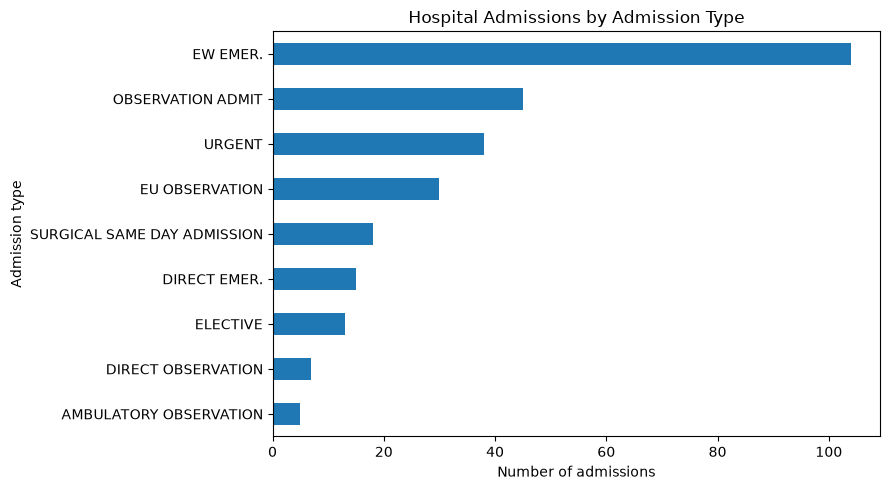

In [12]:
admission_type_counts = (
    visual_df["admission_type"]
    .fillna("Missing")
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 5))
admission_type_counts.plot(kind="barh", ax=ax)
ax.set_title("Hospital Admissions by Admission Type")
ax.set_xlabel("Number of admissions")
ax.set_ylabel("Admission type")
plt.tight_layout()
plt.show()

### Interpretation Prompt

Which admission types dominate the dataset? Does the display show counts or rates? What additional denominator or context might an executive audience need?

## Visualization 2 - Admissions Over Time

A line chart is appropriate because month is ordered and the trend matters.

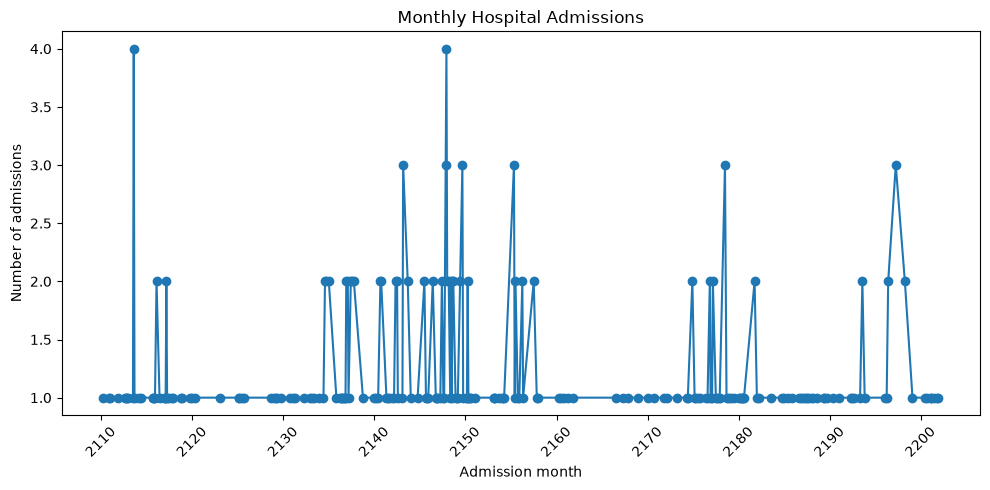

In [16]:
monthly_admissions = (
    visual_df.groupby("admission_month", dropna=False)
    .size()
    .rename("admissions")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_admissions["admission_month"], monthly_admissions["admissions"], marker="o")
ax.set_title("Monthly Hospital Admissions")
ax.set_xlabel("Admission month")
ax.set_ylabel("Number of admissions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Visualization 3 - Hospital Length of Stay

Length of stay is usually right-skewed. A histogram reveals the distribution, while a boxplot highlights the median, spread, and potential outliers.

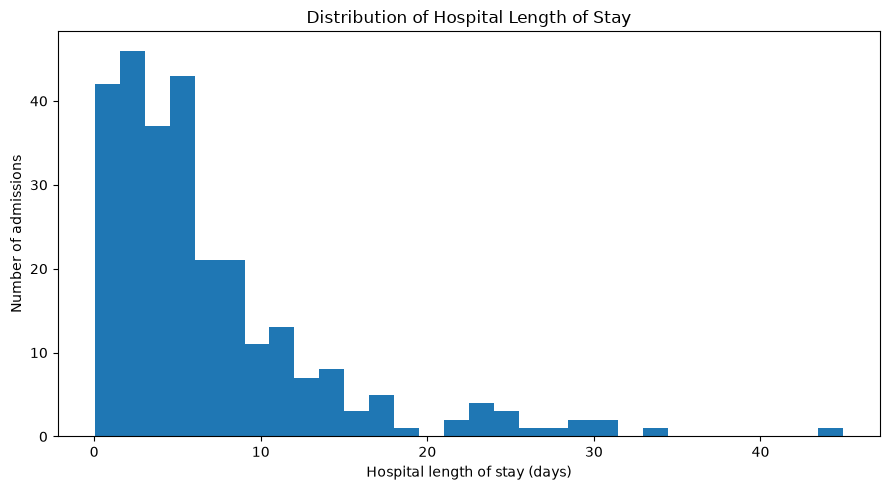

In [17]:
los = visual_df.loc[visual_df["hospital_los_days"].between(0, 60), "hospital_los_days"].dropna()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(los, bins=30)
ax.set_title("Distribution of Hospital Length of Stay")
ax.set_xlabel("Hospital length of stay (days)")
ax.set_ylabel("Number of admissions")
plt.tight_layout()
plt.show()

/tmp/ipykernel_41433/279469036.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(los, vert=False)


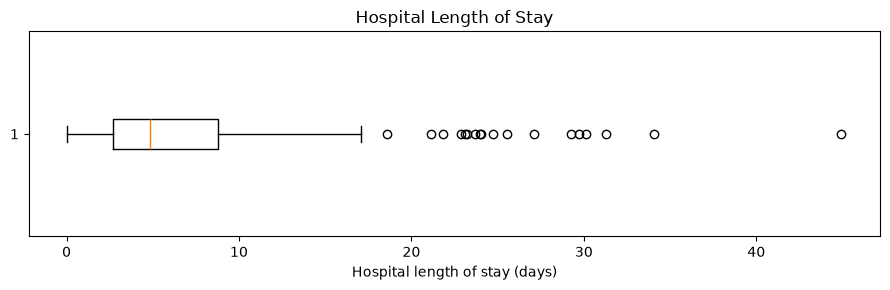

In [18]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.boxplot(los, vert=False)
ax.set_title("Hospital Length of Stay")
ax.set_xlabel("Hospital length of stay (days)")
plt.tight_layout()
plt.show()

## Visualization 4 - Mortality by Admission Type

Rates permit fairer comparison than counts when group sizes differ.

In [19]:
mortality_by_type = (
    visual_df.groupby("admission_type", dropna=False)
    .agg(
        admissions=("hadm_id", "count"),
        deaths=("hospital_expire_flag", "sum"),
        mortality_rate=("hospital_expire_flag", "mean")
    )
    .reset_index()
)
mortality_by_type["mortality_percent"] = mortality_by_type["mortality_rate"] * 100
mortality_by_type.sort_values("mortality_percent", ascending=False)

,admission_type,admissions,deaths,mortality_rate,mortality_percent
8,URGENT,38,5,0.13,13.16
6,OBSERVATION ADMIT,45,3,0.07,6.67
1,DIRECT EMER.,15,1,0.07,6.67
5,EW EMER.,104,6,0.06,5.77
0,AMBULATORY OBSERVATION,5,0,0.00,0.00
4,EU OBSERVATION,30,0,0.00,0.00
3,ELECTIVE,13,0,0.00,0.00
2,DIRECT OBSERVATION,7,0,0.00,0.00
7,SURGICAL SAME DAY ADMISSION,18,0,0.00,0.00


In [ ]:
plot_df = mortality_by_type.sort_values("mortality_percent")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_df["admission_type"].fillna("Missing"), plot_df["mortality_percent"])
ax.set_title("Hospital Mortality by Admission Type")
ax.set_xlabel("Hospital mortality (%)")
ax.set_ylabel("Admission type")
plt.tight_layout()
plt.show()

## Guided Laboratory 1 - Improve a Python Visualization

Create a clear figure showing hospital length of stay by admission type.

Requirements:

- Exclude missing or negative length-of-stay values.
- Limit the display to admission types with at least five admissions.
- Use a boxplot or grouped summary chart.
- Include a meaningful title and units.
- Write a two-sentence interpretation.

In [20]:
# Student workspace: prepare the data.
valid_los = visual_df.loc[
    visual_df["hospital_los_days"].notna()
    & (visual_df["hospital_los_days"] >= 0)
].copy()

admission_type_n = valid_los["admission_type"].value_counts()
eligible_types = admission_type_n[admission_type_n >= 5].index
lab1_df = valid_los[valid_los["admission_type"].isin(eligible_types)].copy()

lab1_df[["admission_type", "hospital_los_days"]].head()

,admission_type,hospital_los_days
0,EW EMER.,2.99
1,EW EMER.,10.39
2,EW EMER.,10.00
3,URGENT,1.74
4,DIRECT EMER.,29.27


In [ ]:
# Student workspace: build the visualization here.

# Part 4 - Prepare the MIMIC-IV Extract for Tableau

Tableau performs best with tidy, analysis-ready data:

- One row per observation
- One column per variable
- Stable keys
- Meaningful field names
- Explicit dates and numeric measures
- Defined missing values

For this module, one row represents one hospital admission.

## Create Tableau-Friendly Labels

Tableau can work with database-style names, but readable field names reduce confusion.

In [21]:
tableau_df = visual_df.rename(columns={
    "subject_id": "Patient ID",
    "hadm_id": "Admission ID",
    "gender": "Gender",
    "anchor_age": "Anchor Age",
    "admittime": "Admission Date Time",
    "dischtime": "Discharge Date Time",
    "admission_date": "Admission Date",
    "admission_month": "Admission Month",
    "admission_year": "Admission Year",
    "admission_type": "Admission Type",
    "admission_location": "Admission Location",
    "discharge_location": "Discharge Location",
    "insurance": "Insurance",
    "language": "Language",
    "marital_status": "Marital Status",
    "race": "Race",
    "hospital_expire_flag": "Hospital Expire Flag",
    "hospital_mortality": "Hospital Mortality",
    "hospital_mortality_rate": "Hospital Mortality Rate",
    "hospital_los_days": "Hospital LOS Days",
    "icu_stay_count": "ICU Stay Count",
    "total_icu_los_days": "Total ICU LOS Days",
    "icu_admission_flag": "ICU Admission",
    "first_careunit": "First Care Unit",
    "principal_icd_code": "Principal ICD Code",
    "principal_icd_version": "Principal ICD Version",
    "principal_diagnosis": "Principal Diagnosis"
})

tableau_df.head()

,Patient ID,Admission ID,Gender,Anchor Age,anchor_year,dod,Admission Date Time,Discharge Date Time,deathtime,Admission Type,Admission Location,Discharge Location,Insurance,Language,Marital Status,Race,Hospital Expire Flag,Hospital LOS Days,ICU Stay Count,Total ICU LOS Days,first_icu_intime,final_icu_outtime,First Care Unit,Principal ICD Code,Principal ICD Version,Principal Diagnosis,Admission Date,Admission Month,Admission Year,ICU Admission,Hospital Mortality,Hospital Mortality Rate
0,10001725,25563031,F,46,2110,NaT,2110-04-11 15:08:00,2110-04-14 15:00:00,NaT,EW EMER.,PACU,HOME,Other,ENGLISH,MARRIED,WHITE,0,2.99,1,1.34,2110-04-11 15:52:22,2110-04-12 23:59:56,Medical/Surgical Intensive Care Unit (MICU/SICU),78829,9,Other specified retention of urine,2110-04-11,2110-04-01,2110,ICU,Survived,0.00
1,10008454,20291550,F,26,2110,NaT,2110-11-30 06:31:00,2110-12-10 15:53:00,NaT,EW EMER.,EMERGENCY ROOM,HOME HEALTH CARE,Other,ENGLISH,SINGLE,WHITE,0,10.39,1,4.98,2110-11-30 17:11:36,2110-12-05 16:48:24,Trauma SICU (TSICU),82111,9,Open fracture of shaft of femur,2110-11-30,2110-11-01,2110,ICU,Survived,0.00
2,10004422,21255400,M,78,2111,NaT,2111-01-15 14:55:00,2111-01-25 15:00:00,NaT,EW EMER.,PROCEDURE SITE,HOME HEALTH CARE,Medicare,ENGLISH,WIDOWED,WHITE,0,10.00,1,6.36,2111-01-17 09:44:50,2111-01-23 18:18:46,Cardiac Vascular Intensive Care Unit (CVICU),41401,9,Coronary atherosclerosis of native coronary ar...,2111-01-15,2111-01-01,2111,ICU,Survived,0.00
3,10006053,22942076,M,52,2111,2111-11-15,2111-11-13 23:39:00,2111-11-15 17:20:00,2111-11-15 17:20:00,URGENT,TRANSFER FROM HOSPITAL,DIED,Medicaid,ENGLISH,NaN,UNKNOWN,1,1.74,2,1.78,2111-11-13 23:40:00,2111-11-15 18:21:10,Medical Intensive Care Unit (MICU),5722,9,Hepatic encephalopathy,2111-11-13,2111-11-01,2111,ICU,Died,1.00
4,10035631,29462354,M,63,2112,2116-03-12,2112-09-17 19:13:00,2112-10-17 01:41:00,NaT,DIRECT EMER.,PHYSICIAN REFERRAL,HOME,Other,ENGLISH,MARRIED,UNKNOWN,0,29.27,0,0.00,NaT,NaT,NaN,20500,9,"Acute myeloid leukemia, without mention of hav...",2112-09-17,2112-09-01,2112,No ICU,Survived,0.00


## Export the Tableau Practice Data

Running this cell creates an extract using the actual MIMIC-IV demo data in your Codespace. Do not upload row-level MIMIC data to a public website unless your course policy explicitly permits it. Tableau Desktop can keep the work local. When using Tableau Public, use only a de-identified or aggregated file approved for public use.

In [22]:
from pathlib import Path

export_directory = Path("module5_outputs")
export_directory.mkdir(exist_ok=True)

row_level_path = export_directory / "HI5312_Module5_MIMIC_Admissions_Tableau.csv"
tableau_df.to_csv(row_level_path, index=False)

print(f"Saved {len(tableau_df):,} rows to {row_level_path}")

Saved 275 rows to module5_outputs/HI5312_Module5_MIMIC_Admissions_Tableau.csv


## Create a Public-Safe Aggregated Extract

This summary contains no patient or admission identifiers. It is suitable for practicing Tableau Public workflows, subject to course policy.

In [ ]:
public_summary = (
    tableau_df.groupby(
        ["Admission Month", "Admission Type", "Insurance", "ICU Admission"],
        dropna=False
    )
    .agg(
        Admissions=("Admission ID", "count"),
        Mean_Hospital_LOS_Days=("Hospital LOS Days", "mean"),
        Median_Hospital_LOS_Days=("Hospital LOS Days", "median"),
        Hospital_Deaths=("Hospital Expire Flag", "sum"),
        Hospital_Mortality_Rate=("Hospital Mortality Rate", "mean"),
        Mean_ICU_LOS_Days=("Total ICU LOS Days", "mean")
    )
    .reset_index()
)

public_summary["Hospital_Mortality_Percent"] = public_summary["Hospital_Mortality_Rate"] * 100
public_summary = public_summary.drop(columns="Hospital_Mortality_Rate")
public_summary.head()

In [ ]:
public_path = export_directory / "HI5312_Module5_MIMIC_Aggregated_Tableau.csv"
public_summary.to_csv(public_path, index=False)
print(f"Saved {len(public_summary):,} aggregated rows to {public_path}")

## Verify the Export

Always reopen the saved file and verify its shape, fields, and data types.

In [ ]:
export_check = pd.read_csv(public_path, parse_dates=["Admission Month"])
print(export_check.shape)
export_check.head()

# Part 5 - Tableau Fundamentals

Tableau organizes the workspace around several concepts:

- **Data source:** The connected file or database
- **Dimensions:** Fields used to categorize or segment data
- **Measures:** Numeric fields that can be aggregated
- **Discrete fields:** Create headers or categories
- **Continuous fields:** Create axes
- **Rows and Columns shelves:** Define the visual structure
- **Marks card:** Controls mark type, color, size, label, detail, and tooltip
- **Filters:** Restrict the displayed data
- **Pages:** Step through values, often time
- **Show Me:** Suggests chart types based on selected fields

## Option A - Connect Tableau to the Aggregated CSV

1. Run the export cells above.
2. Locate `module5_outputs/HI5312_Module5_MIMIC_Aggregated_Tableau.csv`.
3. Download the file from Codespaces to your computer.
4. Open Tableau.
5. Select **Text File**.
6. Choose the CSV.
7. Confirm that `Admission Month` is recognized as a date.
8. Confirm that counts and rates are numeric measures.

## Option B - Connect Tableau Directly to PostgreSQL

Use the direct database connection only when Tableau can reach the Codespaces PostgreSQL service. The hostname `db` works inside the Codespace network but generally is not reachable from Tableau installed on your local computer.

For the standard course workflow, exporting a CSV from the notebook is simpler and more reliable.

## Tableau Worksheet 1 - Admissions by Type

1. Open a new worksheet and rename it **Admissions by Type**.
2. Drag `Admission Type` to **Rows**.
3. Drag `Admissions` to **Columns**.
4. Confirm the aggregation is `SUM`.
5. Sort descending.
6. Turn on mark labels.
7. Add a title that states the comparison.
8. Check for null categories.

## Tableau Worksheet 2 - Admissions Over Time

1. Create a new worksheet named **Admissions Over Time**.
2. Drag `Admission Month` to **Columns**.
3. Choose continuous month.
4. Drag `Admissions` to **Rows**.
5. Set the mark type to **Line**.
6. Drag `Admission Type` to **Color** only if the number of categories remains readable.
7. Add `Insurance` and `ICU Admission` as filters.

## Tableau Worksheet 3 - Mortality by Admission Type

1. Place `Admission Type` on **Rows**.
2. Place `Hospital Mortality Percent` on **Columns**.
3. Because the source is already aggregated, use a weighted calculation rather than averaging percentages across rows.
4. Create the calculated field below.

### Tableau Calculated Field: Weighted Mortality Rate

```text
SUM([Hospital Deaths]) / SUM([Admissions])
```

Format the result as a percentage with one decimal place.

## Why Weighted Rates Matter

A simple average of subgroup percentages gives every subgroup equal weight, even when their denominators differ. The correct overall rate is:

> Total events divided by total observations.

This principle applies to mortality, readmission, complications, and many other healthcare quality measures.

## Tableau Worksheet 4 - Length of Stay

Create a comparison of mean or median hospital length of stay by admission type.

Recommended fields:

- `Admission Type`
- `Admissions`
- `Mean Hospital LOS Days`
- `Median Hospital LOS Days`

Because these values come from an aggregated extract, explain whether the displayed calculation is an average of group means or a directly calculated patient-level summary.

# Part 6 - Tableau Calculated Fields

Calculated fields allow you to create measures, categories, flags, and labels without changing the original source.

## Common Calculated Fields

### Admission volume category

```text
IF SUM([Admissions]) >= 50 THEN "Higher Volume"
ELSE "Lower Volume"
END
```

### Weighted mean hospital length of stay

The aggregated file does not contain the sum of patient-level length of stay, so a perfectly weighted mean cannot be reconstructed from group means alone. This is an important limitation. Use the row-level extract locally when patient-level calculations are required.

### Mortality display label

```text
STR(ROUND(100 * SUM([Hospital Deaths]) / SUM([Admissions]), 1)) + "%"
```

## Student Workspace - Create a Calculated Field

Create a calculated field that identifies whether a group includes ICU admissions.

Your field should return:

- `Includes ICU` when `ICU Admission` equals `ICU`
- `No ICU` otherwise

Record the formula and test it in a worksheet.

# Part 7 - Filters, Parameters, and Interactivity

### Filters
Restrict the displayed records or categories.

### Parameters
User-controlled values that can drive calculations, reference lines, or display choices.

### Actions
Allow one worksheet to filter or highlight another.

Interactivity should help the audience answer questions. It should not be added merely because Tableau supports it.

## Recommended Dashboard Filters

- Admission month range
- Admission type
- Insurance
- ICU admission

Avoid placing every available field on the dashboard. Too many controls increase cognitive load and make the analytic purpose unclear.

## Practice: Add a Date Filter

1. Drag `Admission Month` to the Filters shelf.
2. Select a range of dates.
3. Show the filter.
4. Apply it to all worksheets using the same data source.
5. Confirm that every dashboard component updates consistently.

# Part 8 - Dashboard Design

A dashboard combines multiple views on one screen. Good dashboard design uses hierarchy, alignment, spacing, and restrained emphasis.

### Recommended structure

- Top: title, scope, and key filters
- First row: KPI cards
- Middle: primary trend or comparison
- Bottom: supporting detail
- Footer: source, definitions, exclusions, and refresh date

## KPI Cards

Suggested KPI cards for this module:

- Total admissions
- Hospital mortality rate
- Mean or median hospital length of stay
- Percentage of admissions involving ICU care

KPI cards require context. A number without a comparison period, target, or definition may be difficult to interpret.

## Tableau Dashboard Laboratory

Build a dashboard titled **MIMIC-IV Hospital Utilization Overview** containing:

1. Total admissions KPI
2. Weighted hospital mortality KPI
3. Admissions-over-time line chart
4. Admissions-by-type bar chart
5. Length-of-stay comparison
6. Filters for month, admission type, insurance, and ICU admission
7. A footer describing the MIMIC-IV demo source and analytic limitations

## Dashboard Formatting Checklist

- Is the primary message visible within five seconds?
- Are chart titles specific and meaningful?
- Are units displayed?
- Are bars sorted when ranking matters?
- Are colors used consistently?
- Are filters placed together?
- Is there sufficient white space?
- Are tooltips concise and useful?
- Are denominators clear?
- Are null and missing values addressed?

# Part 9 - Tooltips, Annotations, and Stories

### Tooltips
Tooltips should add context that does not need to remain visible at all times.

### Annotations
Use annotations to direct attention to a meaningful event, threshold, or exception.

### Stories
A Tableau Story sequences views to guide an audience through a narrative. Use stories sparingly; many decision-support products work better as a focused dashboard.

## Three-Part Narrative

Use this structure when presenting your dashboard:

1. **What happened?** Describe the pattern.
2. **Why might it have happened?** Identify plausible explanations without overstating causality.
3. **What should be investigated or done next?** Recommend a specific next analytic or operational step.

# Guided Laboratory 2 - Recreate a Python Chart in Tableau

Recreate the Python admissions-by-type bar chart in Tableau.

Then compare the two tools:

- Which was faster for the initial analysis?
- Which makes interactive filtering easier?
- Which provides more reproducible transformation logic?
- Which is more suitable for an executive audience?

Write a brief conclusion explaining which tool you would use for analysis and which tool you would use for presentation.

# Practice Laboratory - Tableau Skills

Complete the following exercises using the MIMIC-IV extract.

1. Create a sorted bar chart of admissions by type.
2. Create a monthly admissions line chart.
3. Add an admission-type filter.
4. Add an insurance filter.
5. Create a weighted mortality calculation.
6. Format mortality as a percentage.
7. Create a KPI for total admissions.
8. Create a KPI for hospital deaths.
9. Create a length-of-stay comparison.
10. Create a view of ICU versus non-ICU admissions.
11. Build a highlight table using admission type and insurance.
12. Add informative tooltips.
13. Edit a title so it states the finding rather than only the variable names.
14. Apply a date filter to all worksheets.
15. Create a dashboard with at least three worksheets.
16. Add a filter action.
17. Add a data-source and limitations footer.
18. Test the dashboard at laptop resolution.
19. Export the dashboard as a PDF or image.
20. Write a three-sentence interpretation and recommendation.

# Exploration Laboratory

Using the MIMIC-IV data, build an executive dashboard that answers:

- Who was admitted?
- When were admissions highest?
- Which admission types were most common?
- How long did patients remain hospitalized?
- How often did admissions involve ICU care?
- Which patterns deserve additional investigation?

No step-by-step instructions are provided. Your dashboard must include at least four visualizations, two filters, one calculated field, and a limitations statement.

# Clinical Decision Point

Hospital leadership believes ICU utilization is increasing.

Before recommending action, determine:

1. Should the dashboard display ICU admission counts, rates, or both?
2. What denominator defines the ICU utilization rate?
3. Should multiple ICU stays within one admission be counted separately?
4. Which time interval is appropriate?
5. Could admission mix explain the pattern?
6. Which filters would help leaders investigate?
7. What can the dashboard establish, and what would require additional analysis?

Document your definitions before building the display.

# Reflection

Respond in 150-250 words:

How did your role change as you moved from Python analysis to Tableau dashboard development? Discuss the difference between finding a pattern and communicating a pattern responsibly.

# Knowledge Check

1. What is the difference between exploratory and explanatory visualization?
2. Why is a line chart generally preferred for trends over time?
3. When is a histogram more informative than a bar chart?
4. Why can averaging percentages produce an incorrect overall rate?
5. What is the unit of analysis in the Module 5 row-level extract?
6. Why are ICU stays aggregated before joining to admissions?
7. What is the difference between a Tableau dimension and measure?
8. What is the difference between discrete and continuous fields?
9. What should a dashboard footer disclose?
10. Why should color not be the only method for distinguishing groups?
11. When might Tableau Public be inappropriate for row-level healthcare data?
12. What is the purpose of a dashboard action?
13. Why should chart titles communicate meaning rather than repeat field names?
14. What makes a KPI actionable?
15. What is one limitation of the aggregated Tableau extract?

# Stretch Challenge

Create a parameter that allows the dashboard user to switch the primary measure among:

- Admissions
- Hospital mortality rate
- Mean hospital length of stay
- Mean ICU length of stay

Use a calculated field to return the selected measure and update the title dynamically.

# Connection to the Group Project

## Module 5 Deliverable: Interactive Visualization and Dashboard

Each team will:

1. Identify the decision and intended audience.
2. Export the cleaned project data from Module 4.
3. Create at least four Tableau worksheets.
4. Include at least two relevant filters.
5. Create at least one calculated field.
6. Build one integrated dashboard.
7. Include source, refresh date, definitions, and limitations.
8. Present the key finding and a recommended next step.
9. Submit the Tableau workbook or public link, a PDF/image export, and a one-page interpretation.

# Submission Checklist

- [ ] Python 3.12.12 kernel used
- [ ] MIMIC-IV schema verified
- [ ] Admission-level extract validated
- [ ] Tableau-ready CSV created
- [ ] At least four worksheets completed
- [ ] Weighted rate calculation used where appropriate
- [ ] Dashboard filters tested
- [ ] Titles, units, and tooltips reviewed
- [ ] Data source and limitations included
- [ ] Dashboard exported
- [ ] Interpretation and recommendation submitted

# Key Takeaways

- Visualization is part of analysis, not a final cosmetic step.
- Chart choice should follow the question and comparison.
- Counts and rates answer different questions.
- Data structure and aggregation determine what Tableau can calculate correctly.
- Python supports reproducible preparation and verification.
- Tableau supports interactive communication and decision support.
- Responsible dashboards disclose definitions, limitations, and uncertainty.